In [4]:
import os
from openai import OpenAI
from dotenv import load_dotenv
import cv2
import matplotlib.pyplot as plt
from IPython.display import Video, display
import numpy as np
import pandas as pd
import base64

load_dotenv()

True

In [2]:
# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

In [5]:
from openai import OpenAI
client = OpenAI()

In [104]:
# get locations
df_loc = pd.read_csv('../data/P1S3_merged.csv')
df_loc.rename(columns={'Ped_Rotation_x': 'rot_x', 'Ped_Rotation_y': 'rot_y', 'Ped_Rotation_z': 'rot_z'}, inplace=True)

frame_number = 105
df_loc_frames = df_loc.iloc[frame_number:frame_number + 72+1][['timestamp', 'dx', 'dy', 'rot_z']]
df_loc_frames

,timestamp,dx,dy,rot_z
105,3.503500,17.597101,2.282055,-141.321686
106,3.536867,17.582968,2.258998,-144.703140
107,3.570233,17.567858,2.237283,-144.703140
108,3.603600,17.551188,2.217251,-147.214890
109,3.636967,17.532166,2.197966,-150.509171
...,...,...,...,...
173,5.772433,12.447801,0.396258,-66.162514
174,5.805800,12.334634,0.357520,-64.865944
175,5.839167,12.218548,0.320080,-64.095741
176,5.872533,12.103709,0.279034,-65.720558


In [105]:
df_loc_frames.loc[:, 'timestamp'] = df_loc_frames.timestamp - df_loc_frames.timestamp.iloc[-1]
df_loc_frames

,timestamp,dx,dy,rot_z
105,-2.402400,17.597101,2.282055,-141.321686
106,-2.369033,17.582968,2.258998,-144.703140
107,-2.335667,17.567858,2.237283,-144.703140
108,-2.302300,17.551188,2.217251,-147.214890
109,-2.268933,17.532166,2.197966,-150.509171
...,...,...,...,...
173,-0.133467,12.447801,0.396258,-66.162514
174,-0.100100,12.334634,0.357520,-64.865944
175,-0.066733,12.218548,0.320080,-64.095741
176,-0.033367,12.103709,0.279034,-65.720558


In [102]:
df_loc.head()

,timestamp,px_x,px_y,px_u,px_v,Ped_Rotation_x,Ped_Rotation_y,Ped_Rotation_z,dx,dy
0,0.000000,1473.842442,708.768536,749.950697,594.897002,3.486597,4.238080,-43.989124,17.301778,2.895166
1,0.033367,1473.842442,708.768536,749.950697,594.897002,3.486597,4.238080,-43.989124,17.300682,2.894624
2,0.066733,1452.120787,687.978364,761.535580,608.774442,3.185386,2.676370,-45.088326,17.299586,2.894081
3,0.100100,1446.852878,688.129566,764.345132,608.673515,2.950464,1.975176,-45.466831,17.298488,2.893551
4,0.133467,1434.133173,688.481676,771.128975,608.438481,2.576390,1.276243,-46.110001,17.297788,2.893125


In [62]:
df_loc_frames.shape

(73, 3)

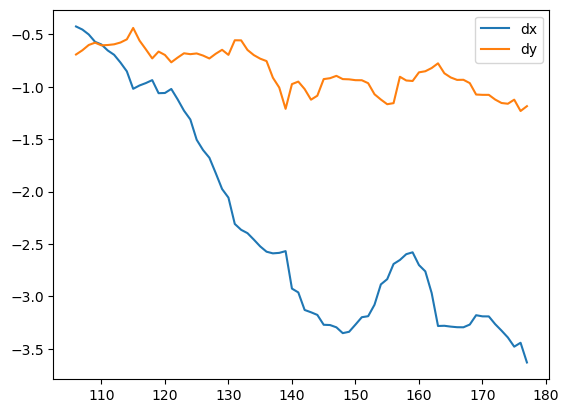

In [45]:
# relative velocity
plt.plot(df_loc_frames.dx.diff()/df_loc_frames.timestamp.diff(), label='dx')
plt.plot(df_loc_frames.dy.diff()/df_loc_frames.timestamp.diff(), label='dy')
plt.legend()

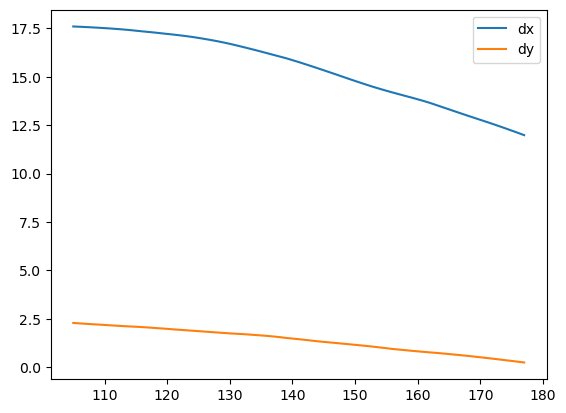

In [46]:
plt.plot(df_loc_frames.dx, label='dx')
plt.plot(df_loc_frames.dy, label='dy')
plt.legend()

In [33]:
locs = list(df_loc_frames.round(3).itertuples(index=False, name=None))
str(locs)

'[(-2.402, 17.597, 2.282), (-2.369, 17.583, 2.259), (-2.336, 17.568, 2.237), (-2.302, 17.551, 2.217), (-2.269, 17.532, 2.198), (-2.236, 17.512, 2.178), (-2.202, 17.491, 2.158), (-2.169, 17.467, 2.138), (-2.135, 17.442, 2.119), (-2.102, 17.413, 2.101), (-2.069, 17.379, 2.086), (-2.035, 17.346, 2.067), (-2.002, 17.314, 2.046), (-1.969, 17.283, 2.022), (-1.935, 17.248, 1.999), (-1.902, 17.212, 1.976), (-1.869, 17.178, 1.951), (-1.835, 17.141, 1.927), (-1.802, 17.1, 1.904), (-1.768, 17.056, 1.881), (-1.735, 17.006, 1.858), (-1.702, 16.953, 1.835), (-1.668, 16.897, 1.811), (-1.635, 16.836, 1.788), (-1.602, 16.77, 1.766), (-1.568, 16.701, 1.743), (-1.535, 16.624, 1.725), (-1.502, 16.546, 1.706), (-1.468, 16.466, 1.684), (-1.435, 16.384, 1.661), (-1.401, 16.299, 1.637), (-1.368, 16.214, 1.612), (-1.335, 16.127, 1.581), (-1.301, 16.041, 1.548), (-1.268, 15.955, 1.507), (-1.235, 15.858, 1.475), (-1.201, 15.759, 1.443), (-1.168, 15.654, 1.409), (-1.134, 15.549, 1.371), (-1.101, 15.443, 1.335), (

In [109]:
rots = list(df_loc_frames[['timestamp', 'rot_z']].round(2).itertuples(index=False, name=None))
str(rots)

'[(-2.4, -141.32), (-2.37, -144.7), (-2.34, -144.7), (-2.3, -147.21), (-2.27, -150.51), (-2.24, -153.78), (-2.2, -153.78), (-2.17, -156.88), (-2.14, -156.88), (-2.1, -157.94), (-2.07, -157.72), (-2.04, -157.72), (-2.0, -157.48), (-1.97, -157.01), (-1.94, -156.54), (-1.9, -156.54), (-1.87, -156.52), (-1.84, -156.52), (-1.8, -156.72), (-1.77, -157.89), (-1.74, -157.89), (-1.7, -157.89), (-1.67, -157.93), (-1.63, -157.93), (-1.6, -158.5), (-1.57, -159.09), (-1.53, -159.27), (-1.5, -159.27), (-1.47, -159.1), (-1.43, -158.72), (-1.4, -158.72), (-1.37, -158.37), (-1.33, -158.19), (-1.3, -158.19), (-1.27, -158.01), (-1.23, -158.01), (-1.2, -158.77), (-1.17, -158.65), (-1.13, -157.64), (-1.1, -157.64), (-1.07, -158.52), (-1.03, -158.52), (-1.0, -159.2), (-0.97, -158.39), (-0.93, -158.39), (-0.9, -157.54), (-0.87, -156.29), (-0.83, -156.29), (-0.8, -154.8), (-0.77, -143.33), (-0.73, -143.33), (-0.7, -132.55), (-0.67, -113.04), (-0.63, -113.04), (-0.6, -106.95), (-0.57, -91.8), (-0.53, -91.8), (

In [34]:
df_loc_frames

,timestamp,dx,dy
105,-2.402400,17.597101,2.282055
106,-2.369033,17.582968,2.258998
107,-2.335667,17.567858,2.237283
108,-2.302300,17.551188,2.217251
109,-2.268933,17.532166,2.197966
...,...,...,...
173,-0.133467,12.447801,0.396258
174,-0.100100,12.334634,0.357520
175,-0.066733,12.218548,0.320080
176,-0.033367,12.103709,0.279034


In [49]:
df_loc_frames.loc[frame_number+51]

timestamp    -0.700700
dx           14.186515
dy            0.936904
Name: 156, dtype: float64

In [165]:
file = 'P1S3'
frames_list = [
    frame_number, frame_number+9, frame_number+18,
    frame_number+27, frame_number+36, frame_number+45,
    frame_number+48, frame_number+51, frame_number+53,
    frame_number+57, frame_number+60, frame_number+63,
    frame_number+66, frame_number+69, frame_number+72,
]

images = []
for f in frames_list:
    images.append({"path": f"../data/videoframes/{file}/frame_000{f:03d}.jpg", "time elapsed": round(df_loc_frames.loc[f].timestamp.item(), 2)})

images
image_messages = []
image_messages.append({"type": "input_text", "text": "Images at the following time elapsed (in seconds):" + str([round(img['time elapsed'], 2) for img in images]) + "."})
for img in images:
    image_messages.append({"type": "input_image", "image_url": f"data:image/jpeg;base64,{encode_image(img['path'])}", "detail": "low"})

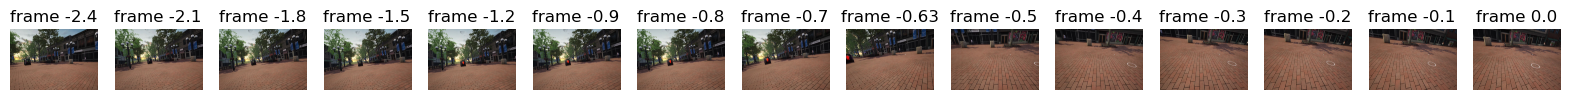

In [166]:
fig, axs = plt.subplots(1, len(images), figsize=(20, 5))
for ax, imgfile in zip(axs, images):
    # read image
    img_data = cv2.imread(imgfile['path'])
    img_data = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)
    ax.imshow(img_data)
    ax.set_title(f'frame {imgfile["time elapsed"]}')
    ax.axis('off')
plt.show()

[{'type': 'input_text',
  'text': "\nYou are a pedestrian wearing a first-person camera. Your job is to predict **your walking action in the next 1 s**. Summarize your rationale in 3–5 sentences.\n\n   **Available actions (choose exactly one at the end):**\n\n   - Accelerate to the goal  \n   - Maintain current speed  \n   - Decelerate to the goal  \n   - Stop  \n   - Step backward to be away from the goal  \n\n---\nExtra guidance question: \n- What's the pod movement based on the relative sizes in sequences? \n- Is your path and pod's path intersecting?\n- If both your and the pod kept moving constantly, would you collide?\n"},
 {'type': 'input_text',
  'text': 'Images at the following time elapsed (in seconds):[-2.4, -2.1, -1.8, -1.5, -1.2, -0.9, -0.8, -0.7, -0.63, -0.5, -0.4, -0.3, -0.2, -0.1, 0.0].'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_image',
  'image_url': '',
  'detail': 'low'},
 {'type': 'input_image',
  'image_url': '',
  'detail':
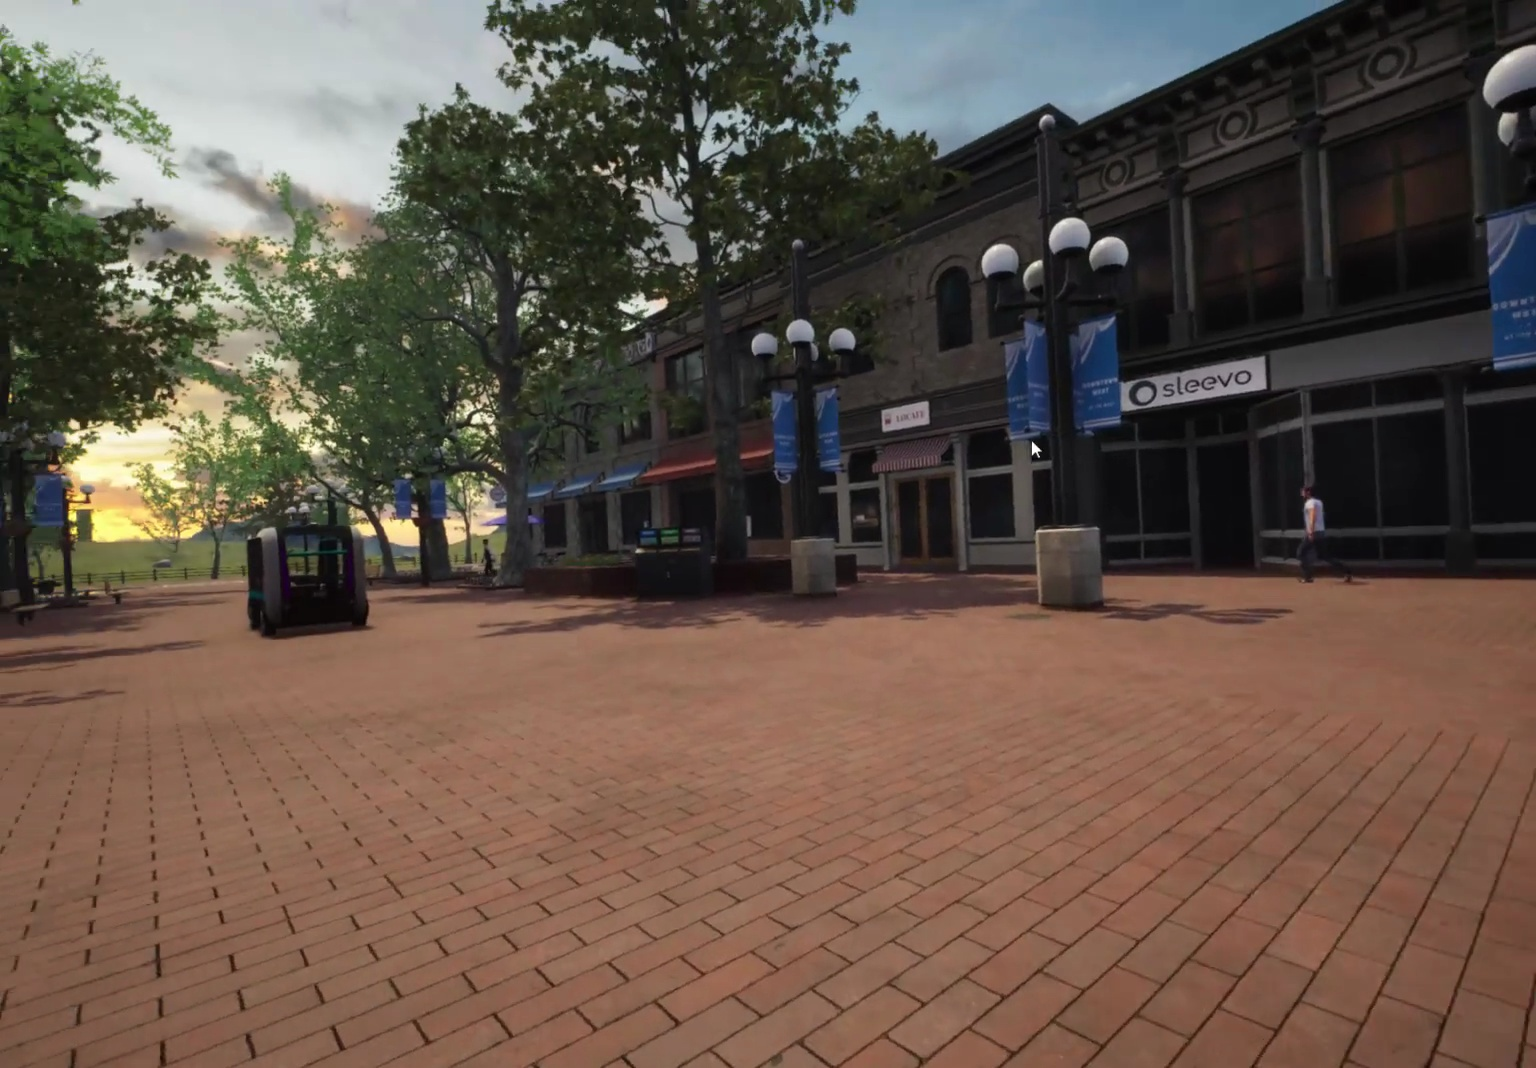
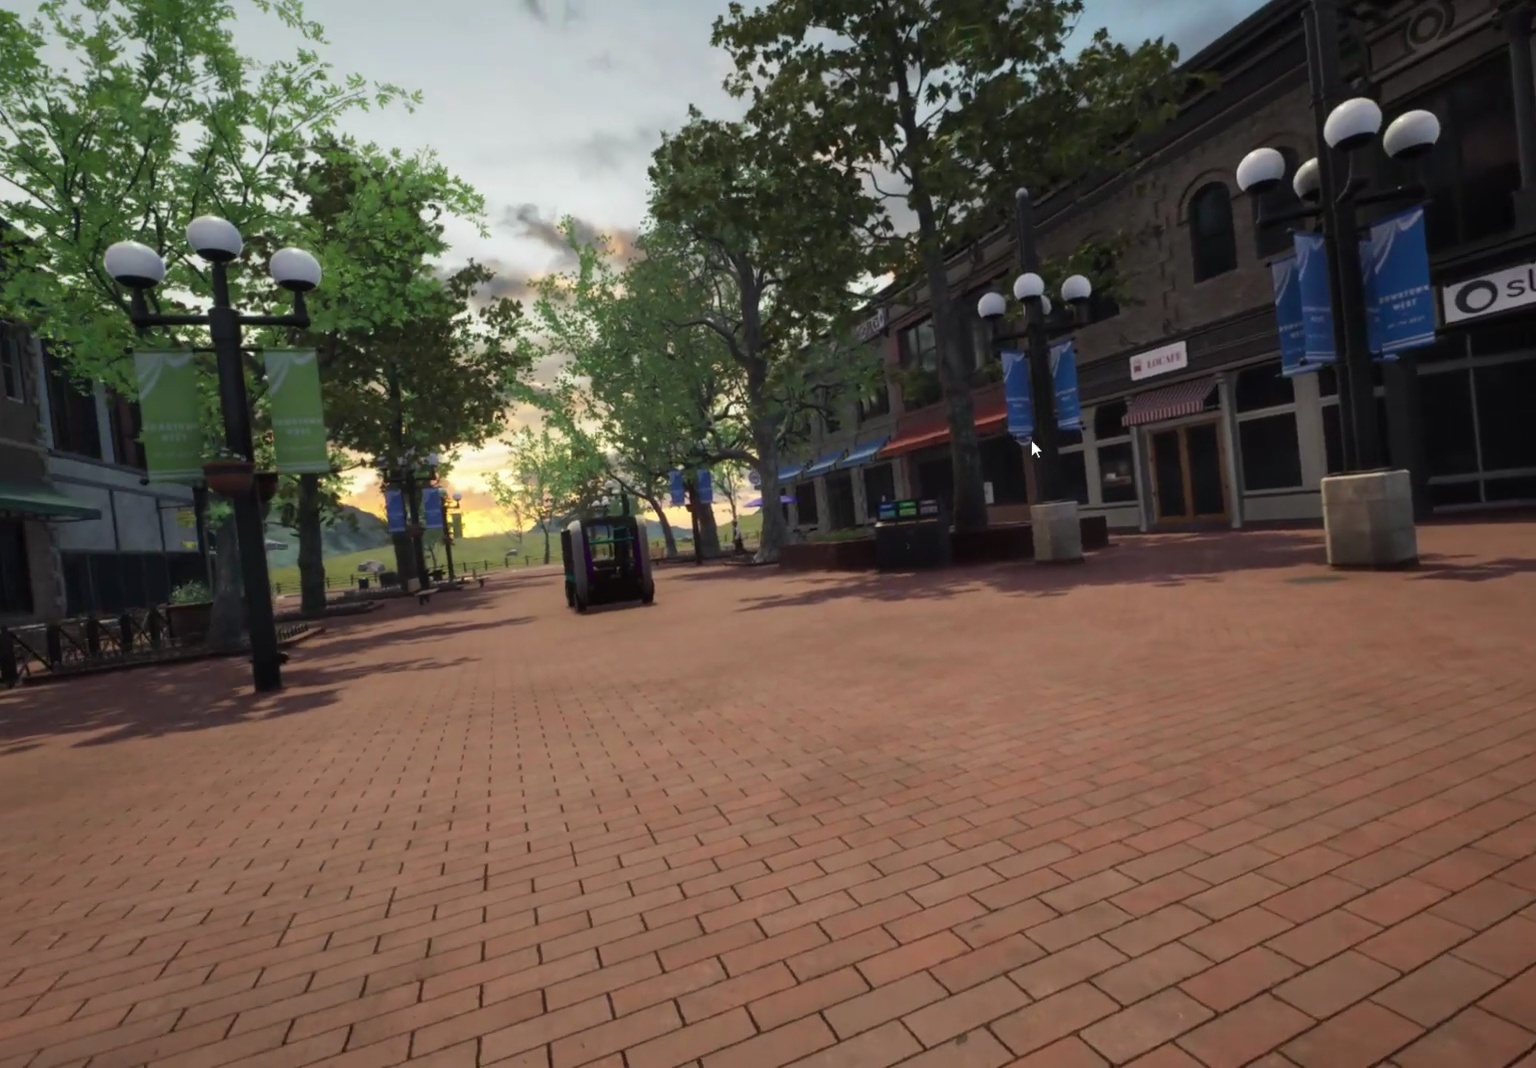
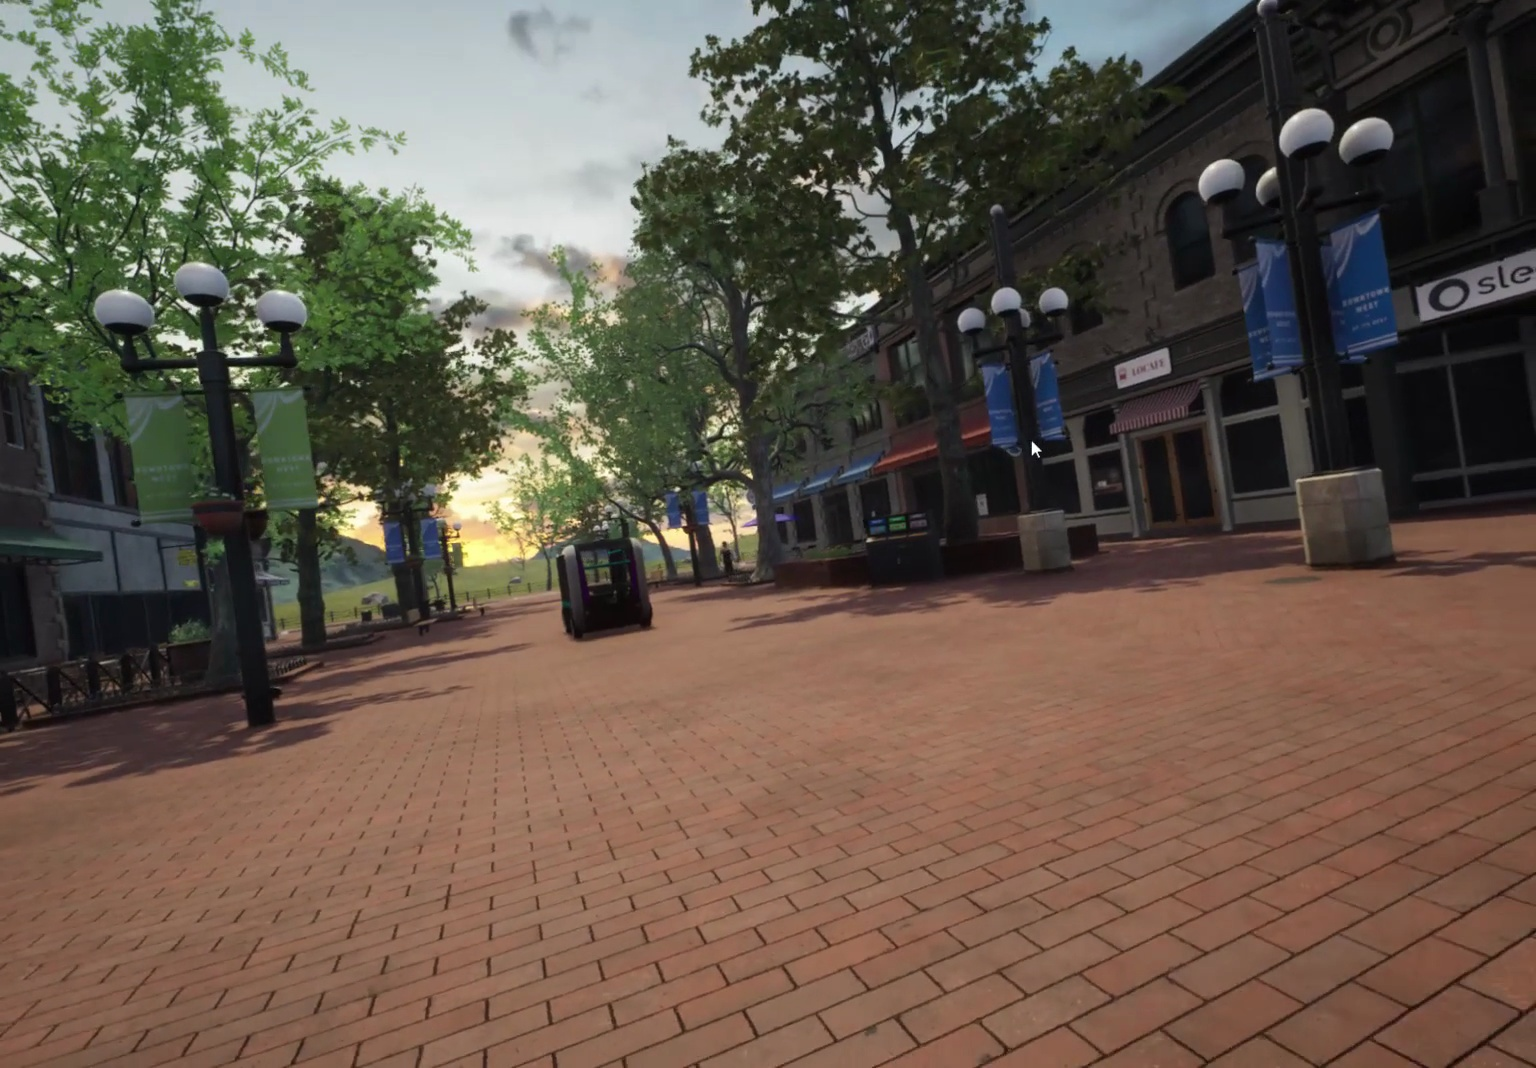
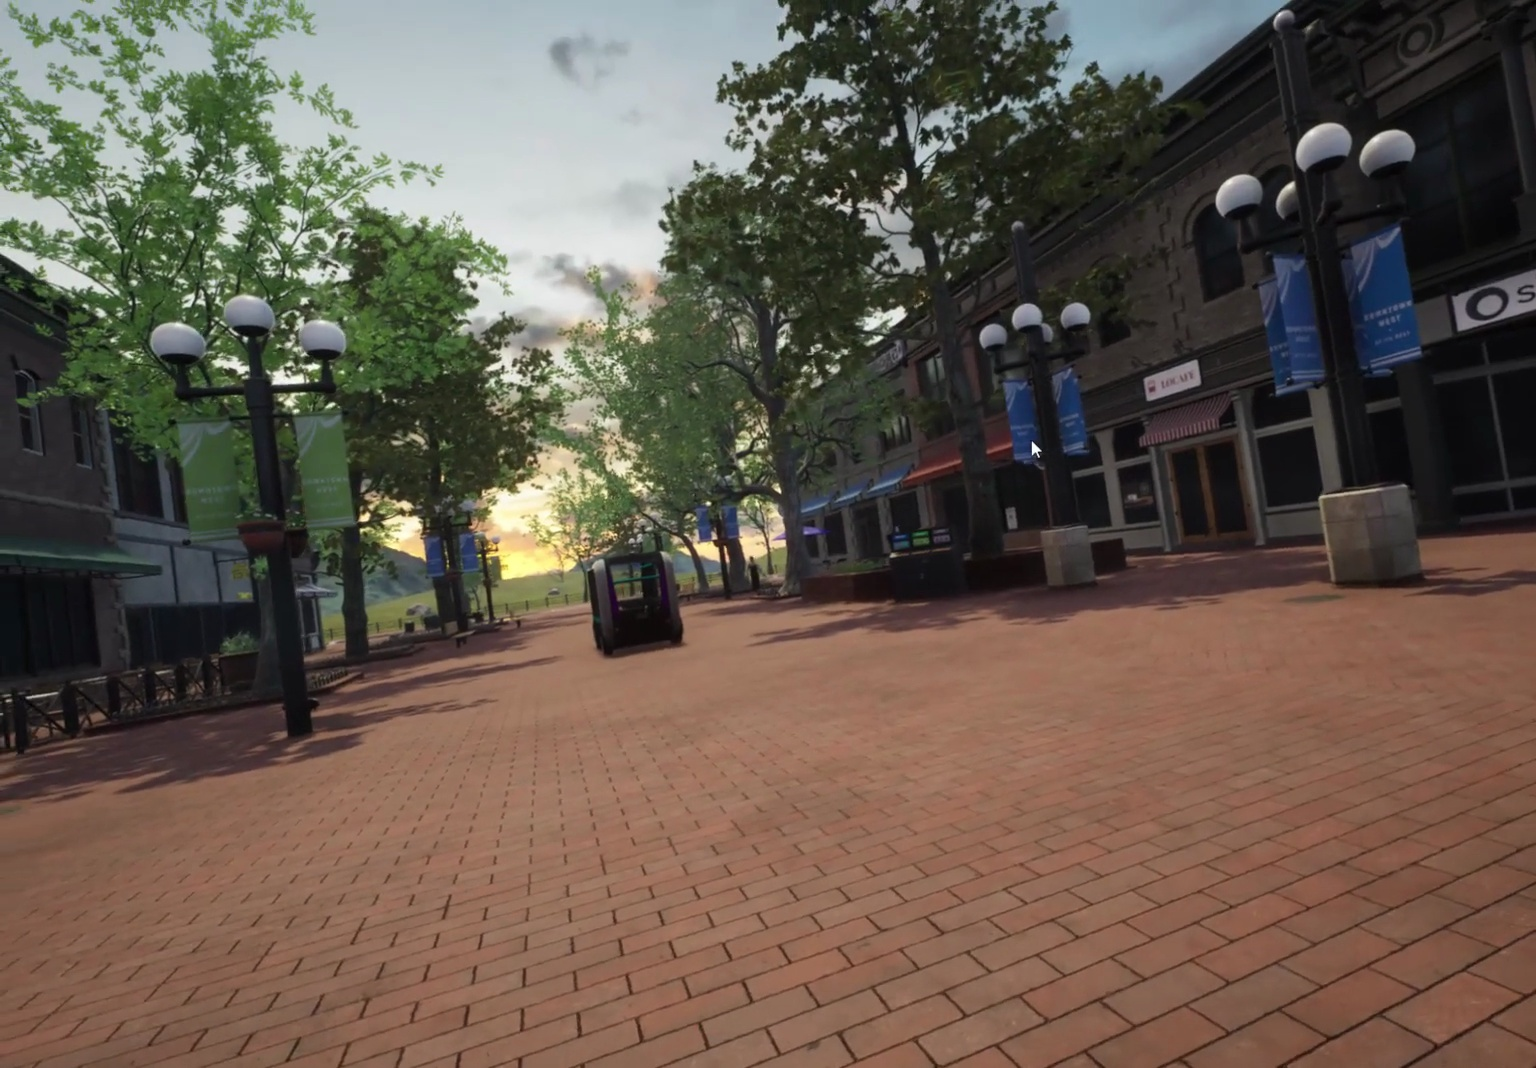
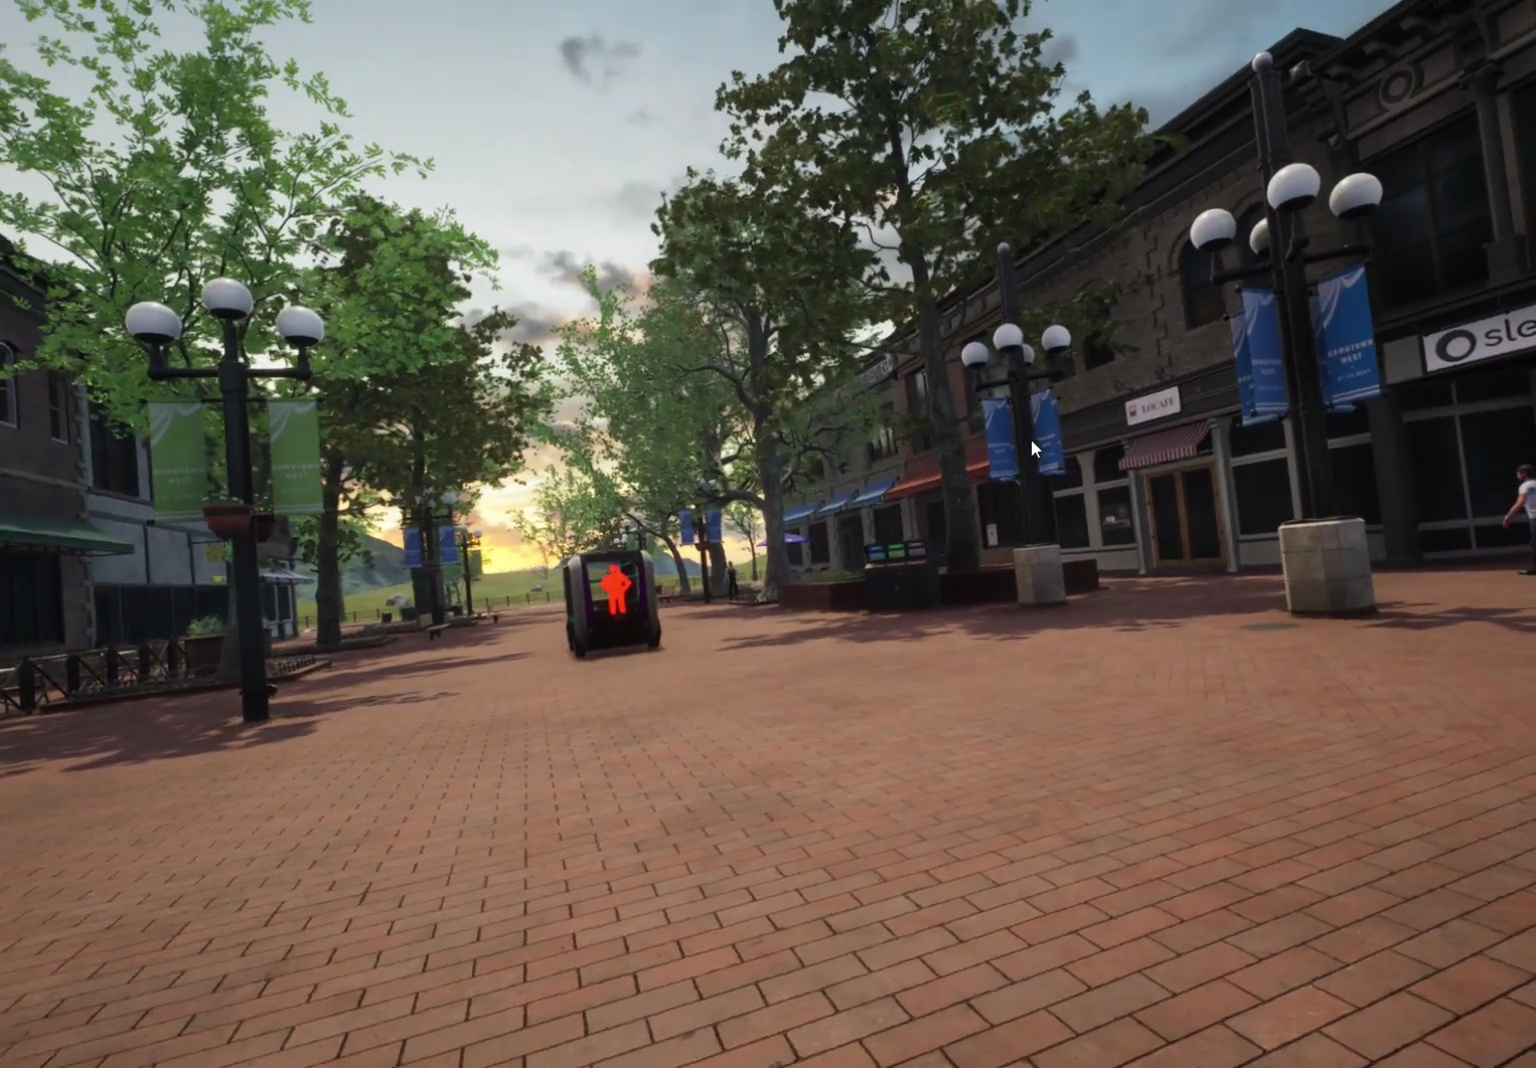
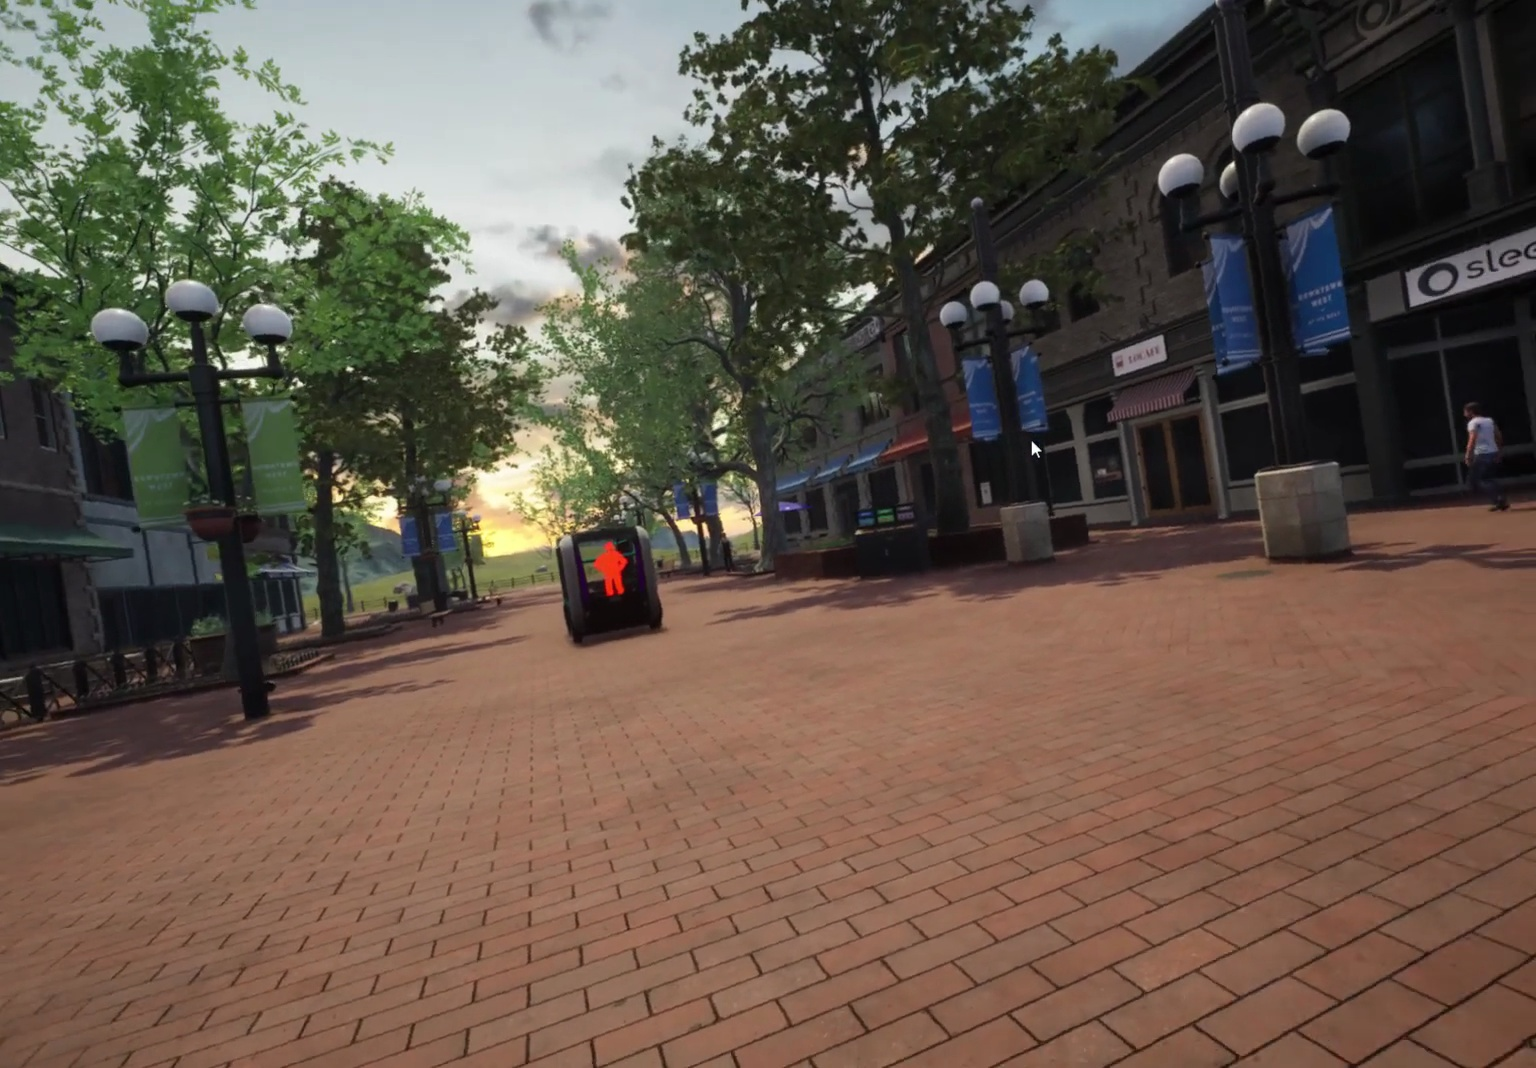
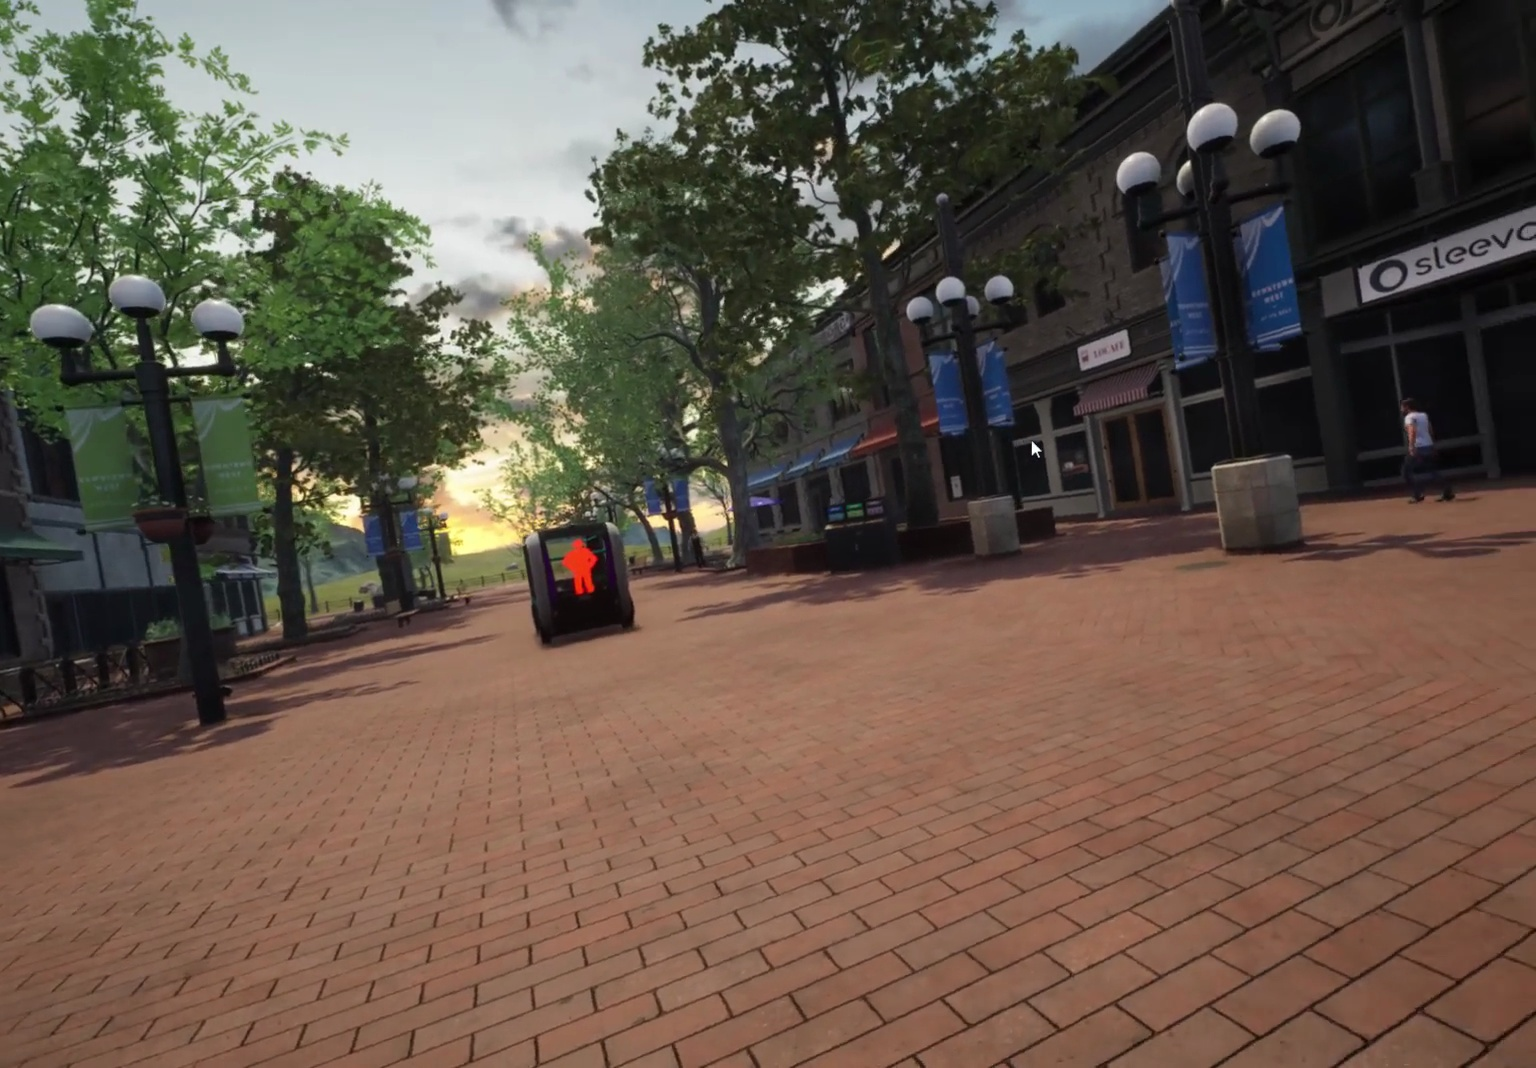
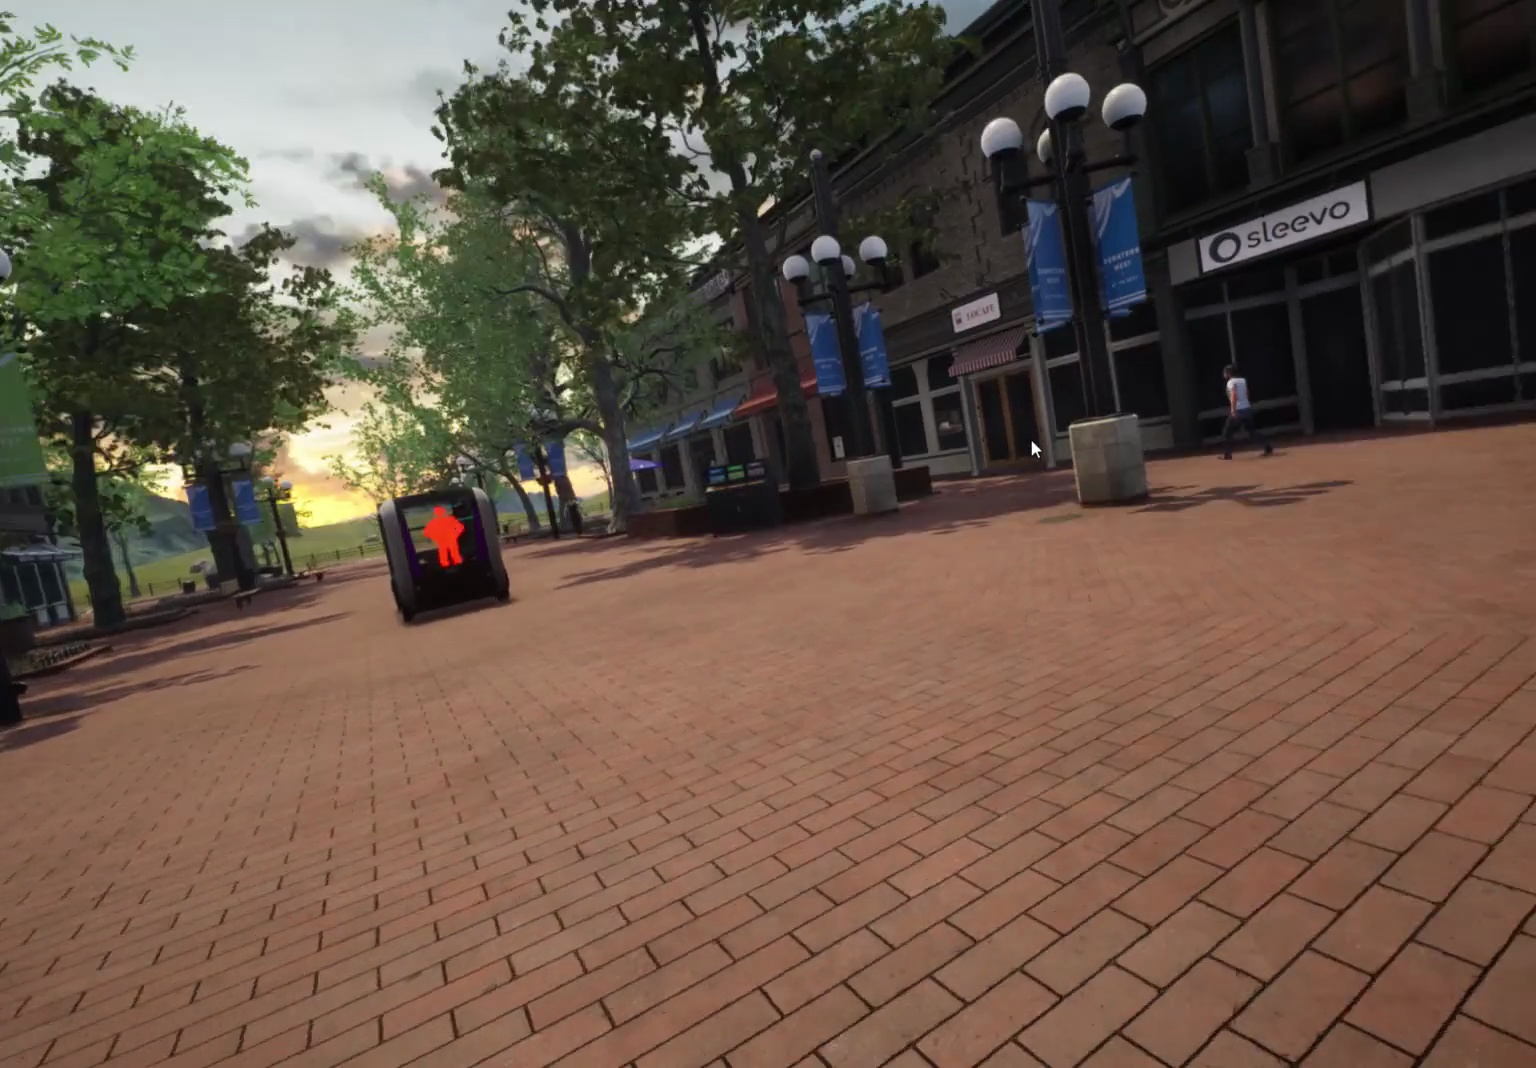
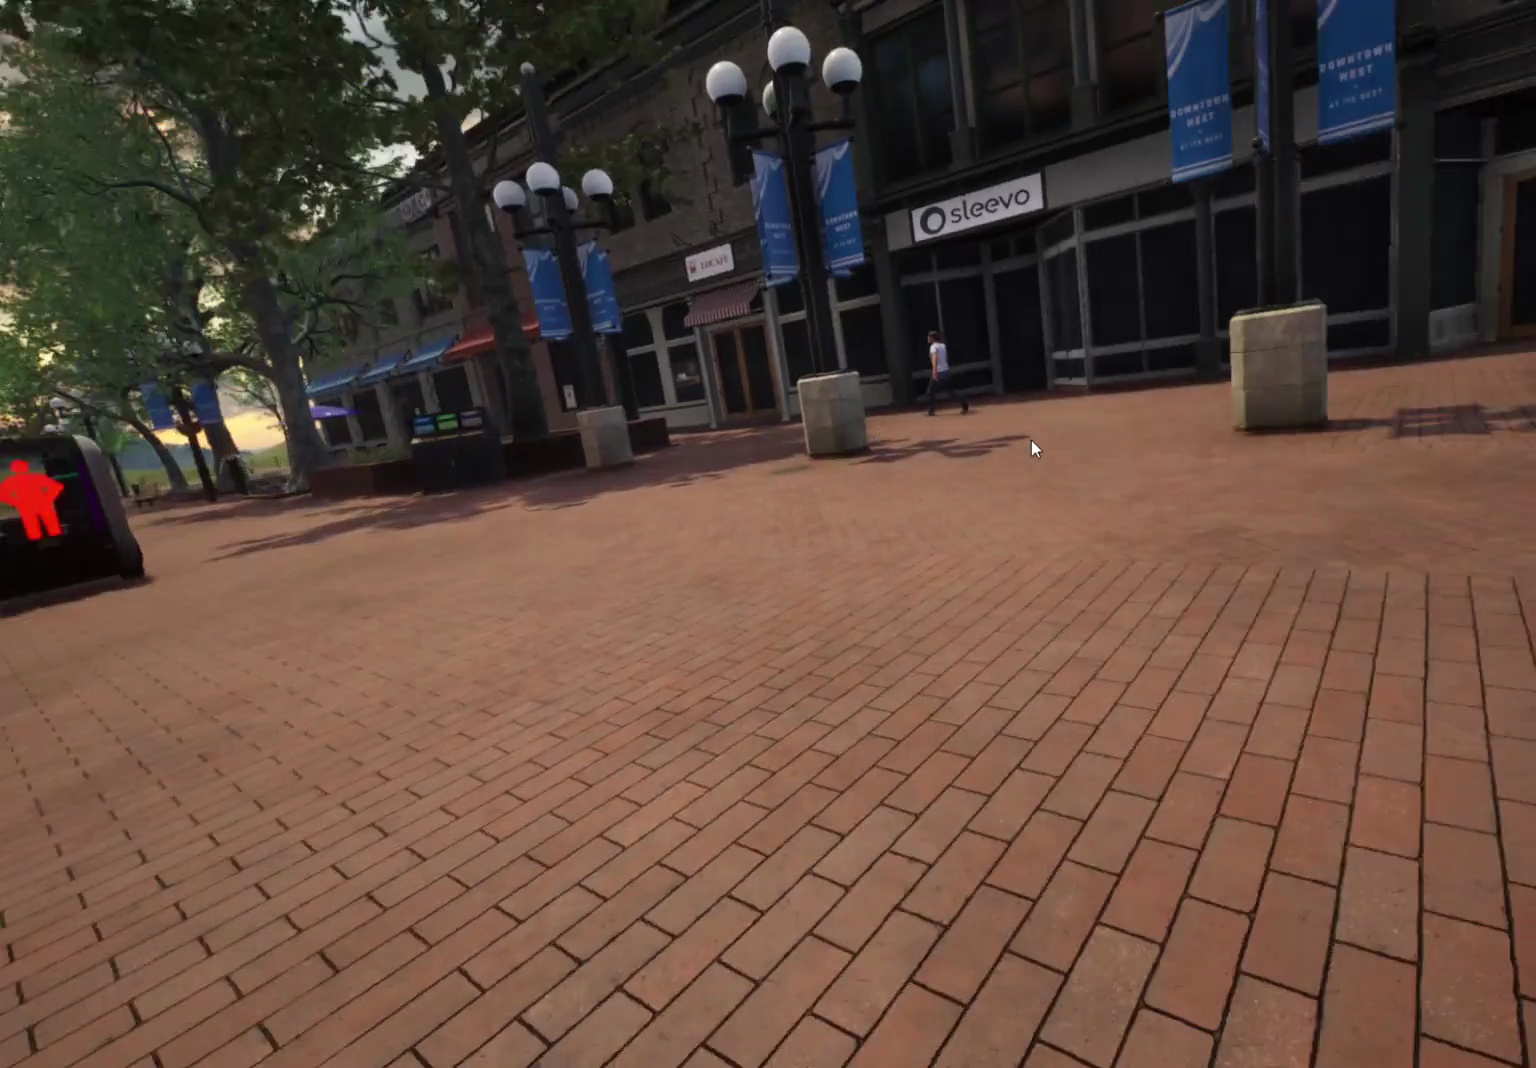
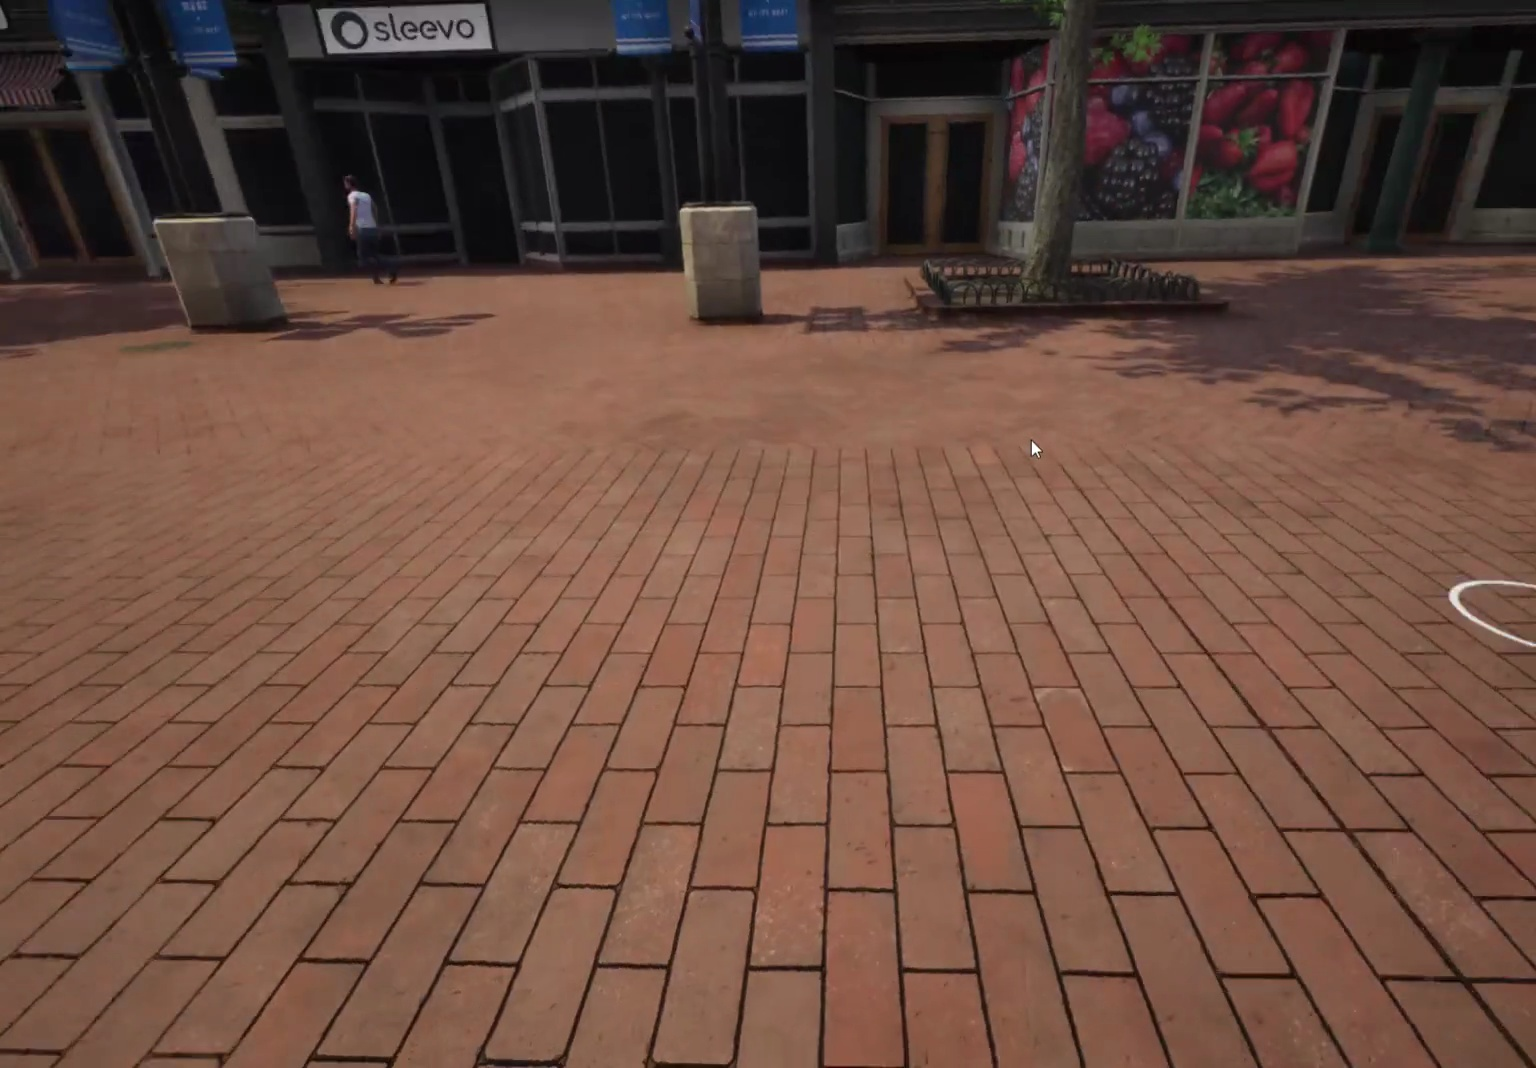
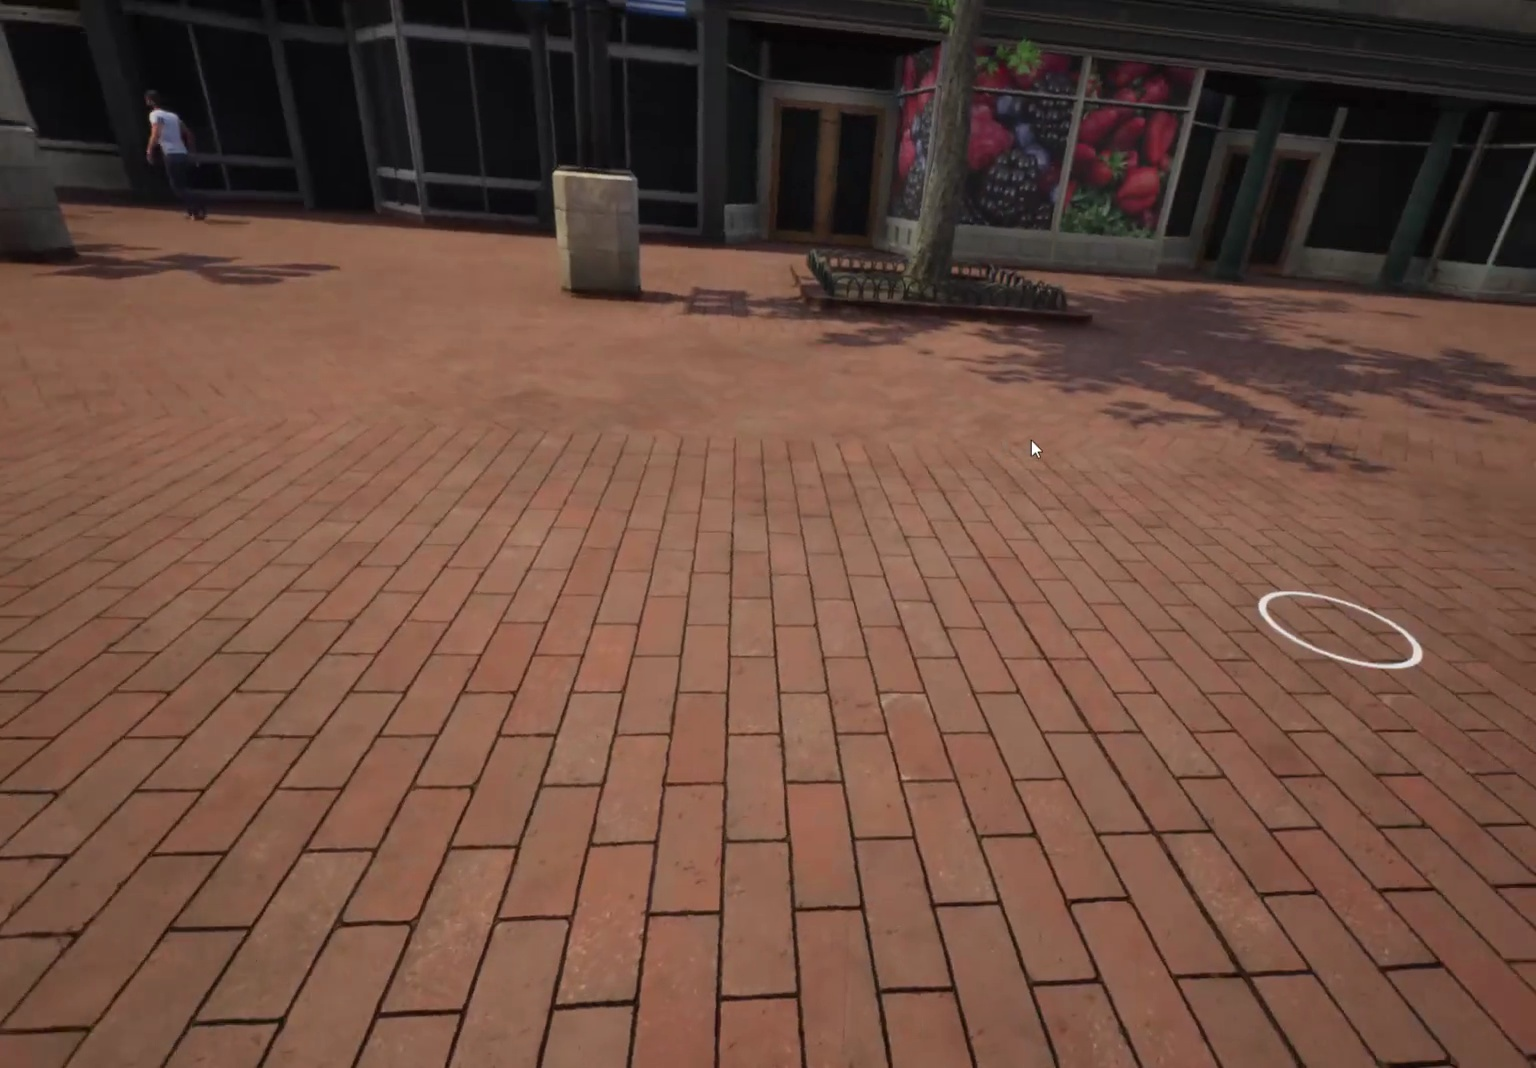
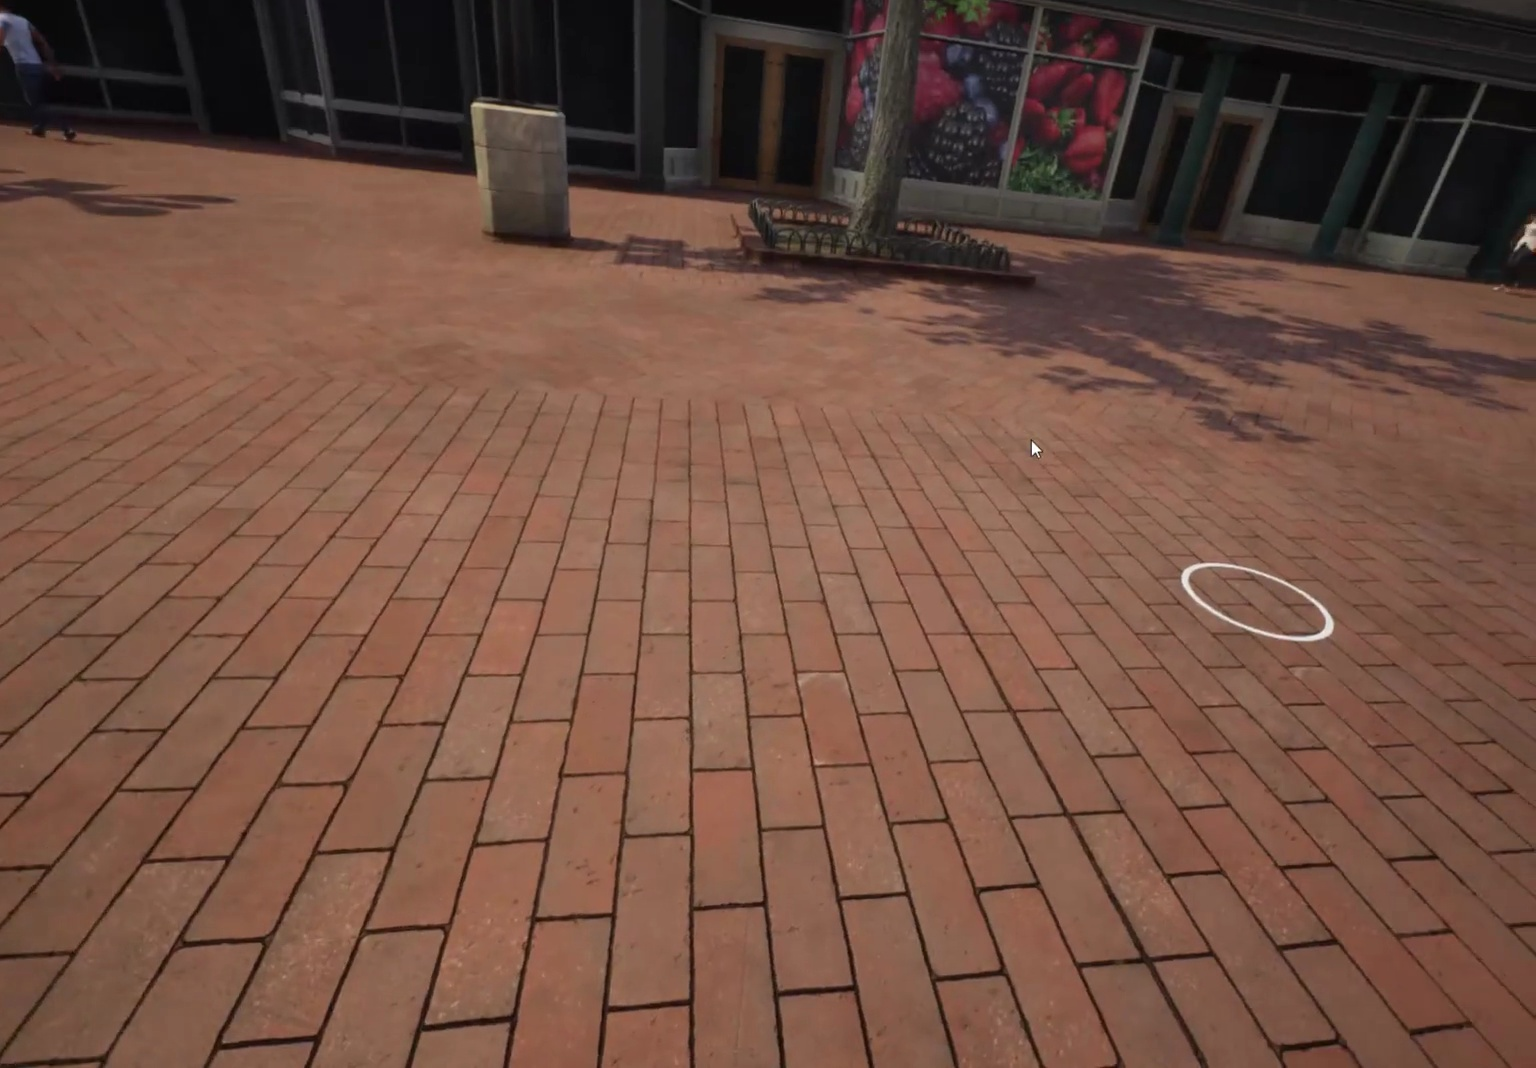
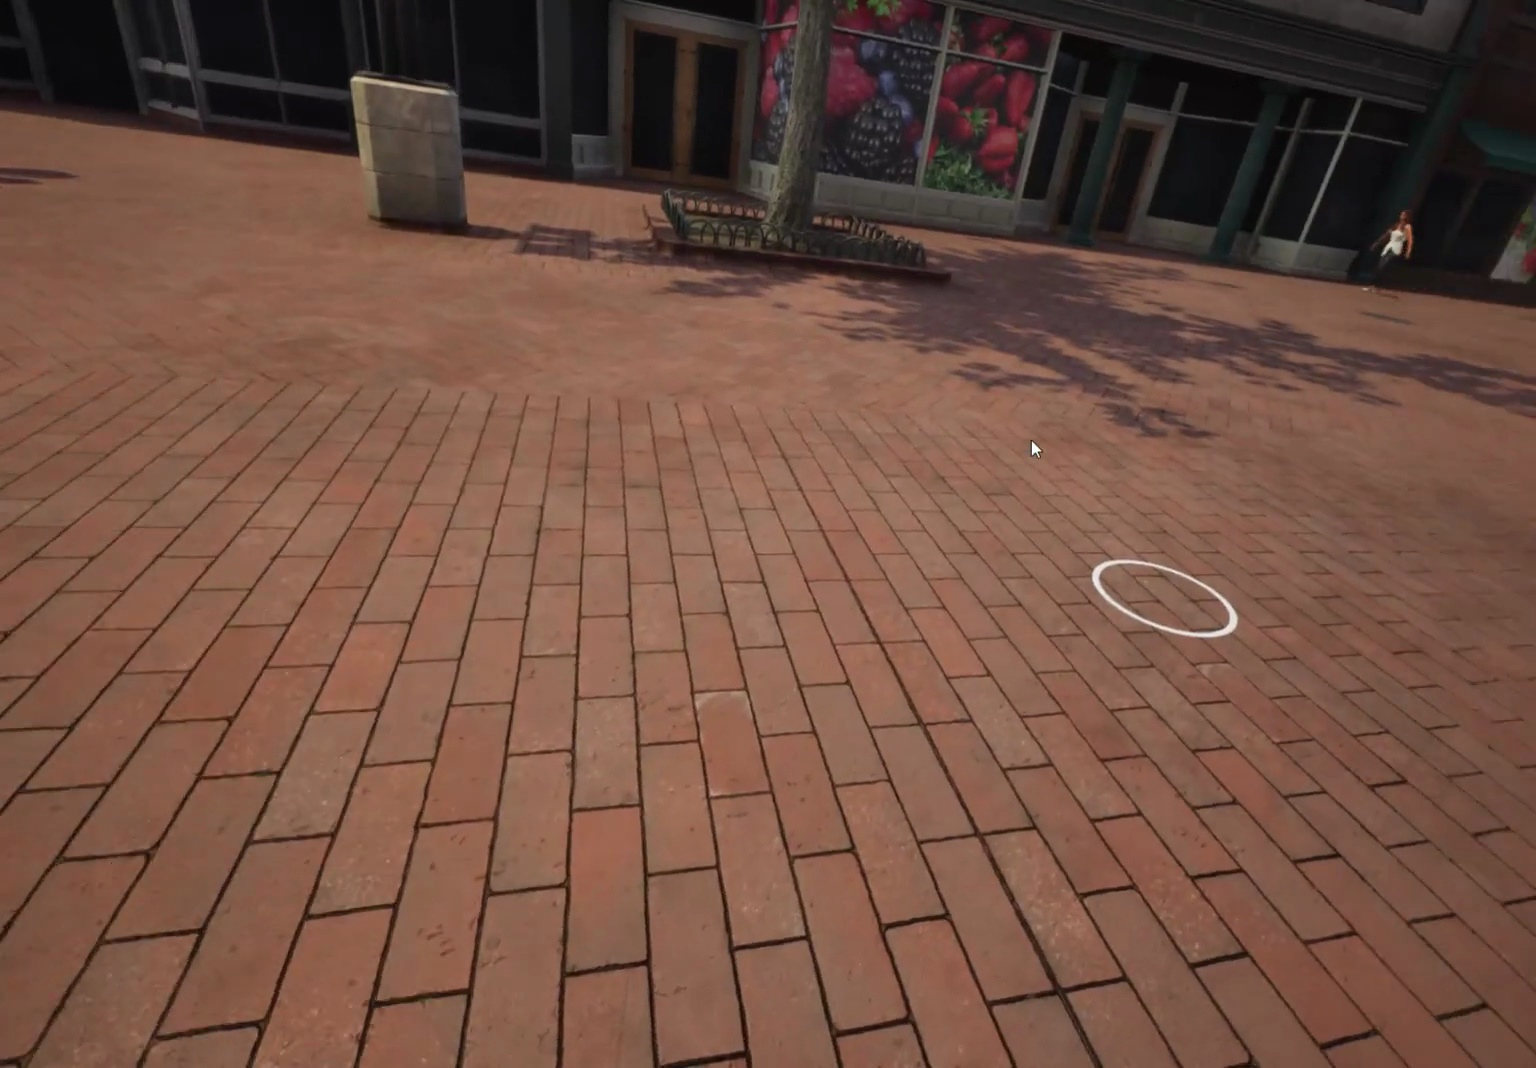
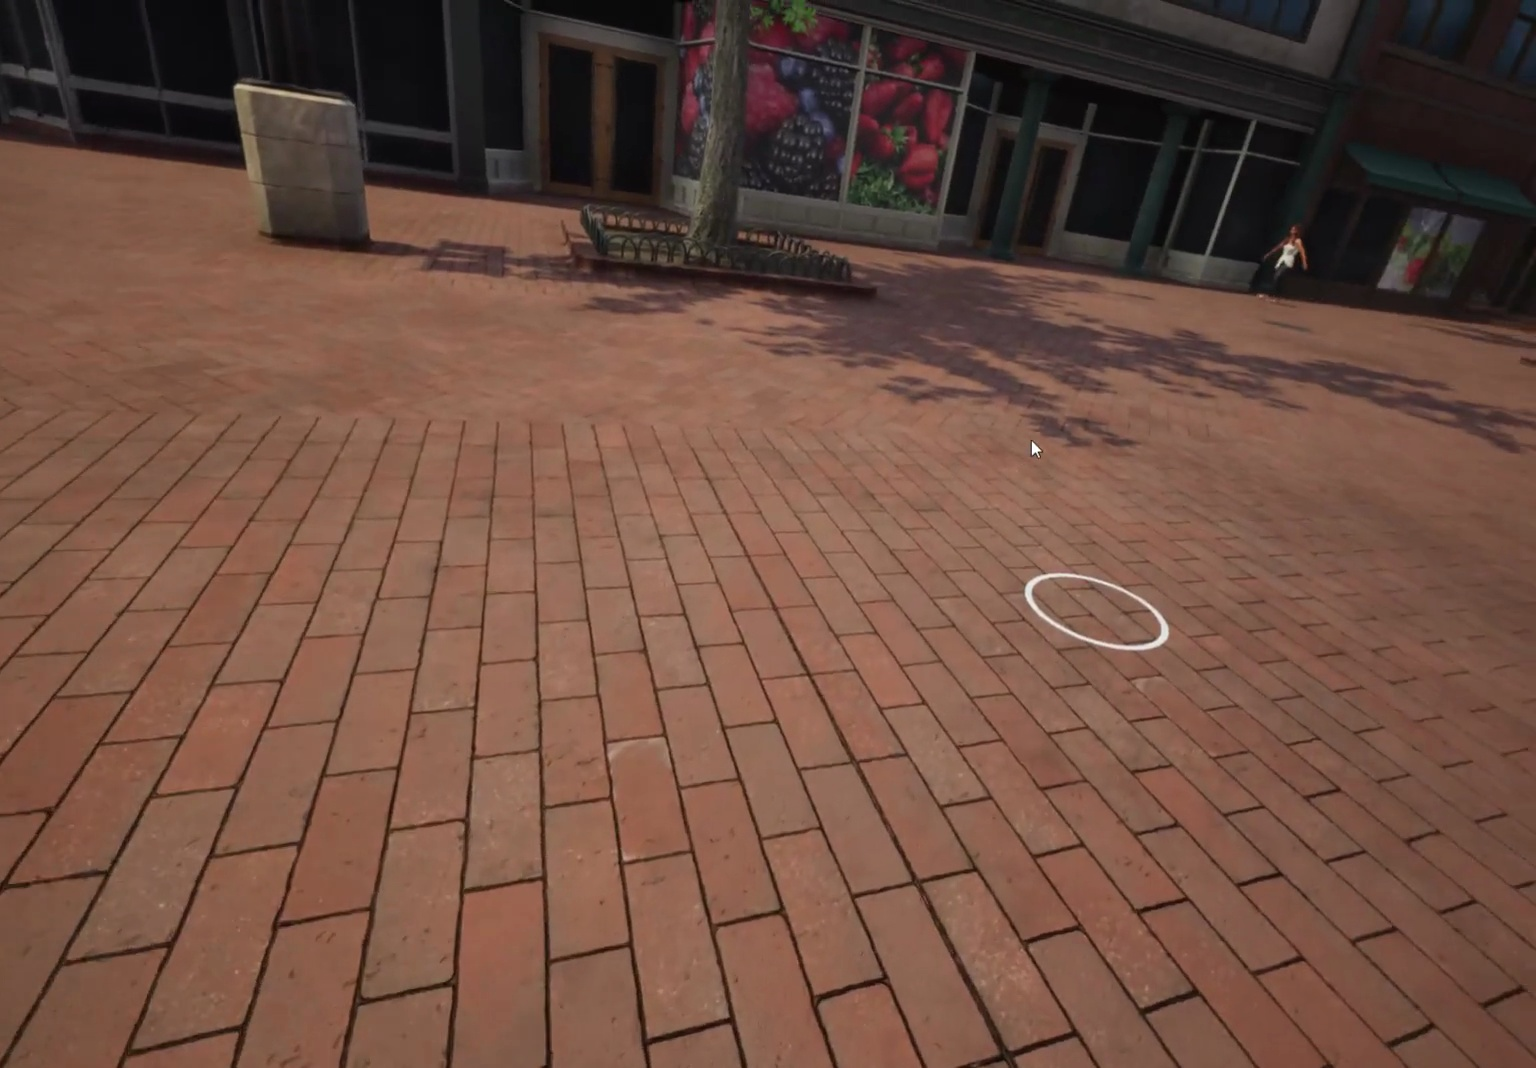
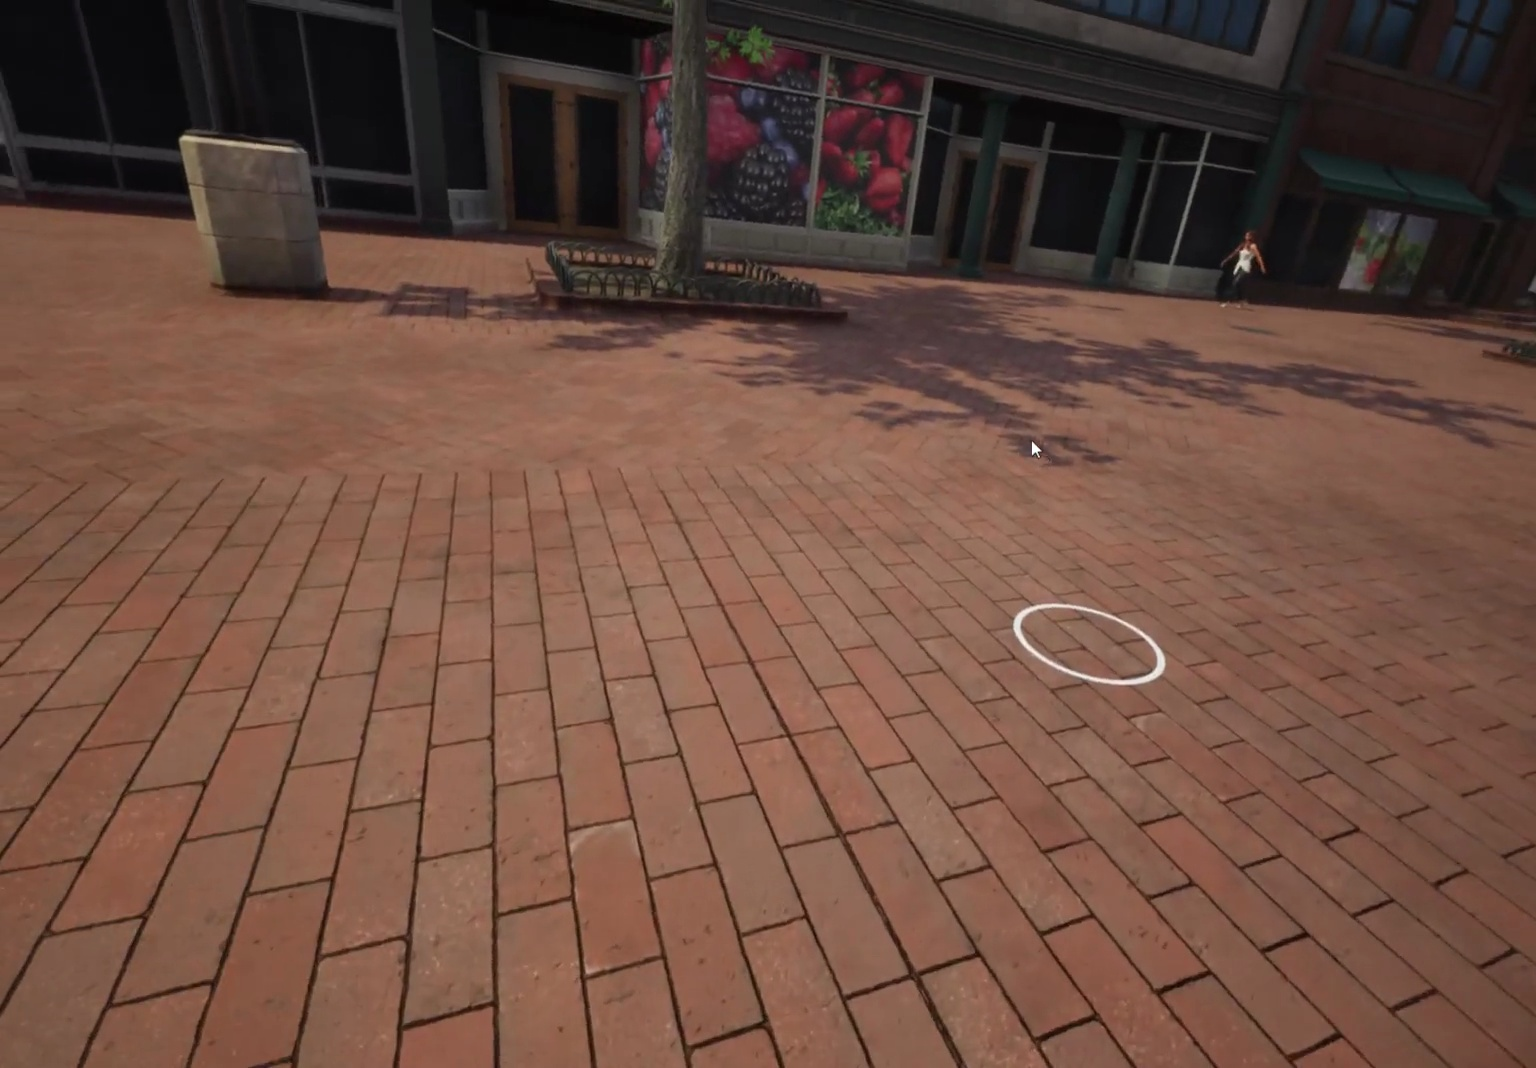

In [234]:
content = [
    {
        "type": "input_text",
        "text": f'''
You are a pedestrian wearing a first-person camera. Your job is to predict **your walking action in the next 1 s**. Summarize your rationale in 3–5 sentences.

   **Available actions (choose exactly one at the end):**

   - Accelerate to the goal  
   - Maintain current speed  
   - Decelerate to the goal  
   - Stop  
   - Step backward to be away from the goal  
   
---
Extra guidance question: 
- What's the pod movement based on the relative sizes in sequences? 
- Is your path and pod's path intersecting?
- If both your and the pod kept moving constantly, would you collide?
'''}
]
content.extend(image_messages)

content

In [235]:
%%time
response = client.responses.create(
    model="gpt-5.1",
    input=[
        {
            "role": "user",
            "content": content,
        }
    ],
    reasoning={ "effort": "low" },
)

CPU times: user 82 ms, sys: 42.7 ms, total: 125 ms
Wall time: 7.39 s


APIConnectionError: Connection error.

In [ ]:
print(response.output_text)

The pod ahead remains at a roughly constant size and then shifts leftwards, indicating it is moving away from our future path rather than toward us. Throughout the sequence there is ample space and no sign of imminent collision or sudden pod acceleration toward us. By the final frames our attention and goal marker are on the right, with the pod clearly separated on the left, so no evasive action is needed.  

**Action: Maintain current speed**


## Diagnosis

In [204]:
prompt = """
You are a prompt diagnostics assistant. 

Based on our first input, the previous output is not expected as ground truth. The true top-down view relationship should be something like this:  

          N (−Y)
          ↑
          │            Buildings / shops
          │  ----------------------------------------------------------------
          |  Park / open plaza
          |
          │                                          GOAL ○ (white circle)
          │ pod path →   →   →
          │  P(t<0)   P(now)              •
          │                              YOU (camera)
          │ 
          │ 
          │ ----------------------------------------------------------------
          │             Buildings / shops                  
          └────────────────────────────────────────────→ E (+X)
                 (south side, +Y)

Your task: 
1. Identify why the model fails in this understanding. 
2. Identify which parts of my prompt may have caused the issue. 
3. Suggest how to rewrite the prompt to avoid the failure.
"""
prompt

'\nYou are a prompt diagnostics assistant. \n\nBased on our first input, the previous output is not expected as ground truth. The true top-down view relationship should be something like this:  \n\n          N (−Y)\n          ↑\n          │            Buildings / shops\n          │  ----------------------------------------------------------------\n          |  Park / open plaza\n          |\n          │                                          GOAL ○ (white circle)\n          │ pod path →   →   →\n          │  P(t<0)   P(now)              •\n          │                              YOU (camera)\n          │ \n          │ \n          │ ----------------------------------------------------------------\n          │             Buildings / shops                  \n          └────────────────────────────────────────────→ E (+X)\n                 (south side, +Y)\n\nYour task: \n1. Identify why the model fails in this understanding. \n2. Identify which parts of my prompt may have caused the i

In [205]:
%%time
res = client.responses.create(
    model="gpt-5.1",
    input=[
        {
            "role": "user",
            "content": content,
        },
        {
            "role": "system",
            "content": response.output_text
        },
        {
            "role": "user",
            "content": prompt,
        }
    ],
    reasoning={ "effort": "low" },
)

CPU times: user 40.3 ms, sys: 36.7 ms, total: 77 ms
Wall time: 1min 4s


In [206]:
print(res.output_text)

1. **Why the model failed**

   - **Misinterpreted your own coordinate explanation.**  
     I assumed the observer was *east* of the pod looking west, not *south* of the pod looking north, so I put you and the goal on the wrong side of the pod’s path.

   - **Incorrect use of head‑angle convention.**  
     With 0° = facing east and positive clockwise, an angle around −150° points roughly northwest. In the images, when the pod is centered, your gaze is actually more “north-ish” from a point south of the pod. I didn’t re‑derive this carefully against all frames; I matched angles loosely to what “felt” right visually.

   - **Did not fully enforce the “pod moves east with front screen on east side” constraint.**  
     My layout had you east of the pod but still looking at its rear/front inconsistently; this contradicts the statement that signals show on the (east) front screen while the pod moves west→east.

   - **Over-weighted image intuition vs. your logical constraints.**  
     Ev